# Explorative Datenanalyse (EDA) – HMEQ Home Equity Dataset

**Quelle:** [Kaggle – HMEQ Data](https://www.kaggle.com/datasets/ajay1735/hmeq-data)

Der Datensatz enthält Angaben zu **5.960 Home-Equity-Krediten** (Kredite, die durch den Eigenkapitalanteil
einer Immobilie besichert sind). Zielvariable ist `BAD`: ob der Kreditnehmer ausgefallen ist bzw. stark im
Zahlungsverzug war (1) oder den Kredit ordnungsgemäß bedient (0).

| Spalte | Beschreibung |
|---|---|
| `BAD` | **Zielvariable:** 1 = Kredit ausgefallen / schwerwiegend in Verzug, 0 = Kredit zurückgezahlt |
| `LOAN` | Beantragter Kreditbetrag |
| `MORTDUE` | Ausstehender Betrag der bestehenden Hypothek |
| `VALUE` | Wert der Immobilie |
| `REASON` | Kreditzweck: `DebtCon` = Umschuldung, `HomeImp` = Renovierung/Modernisierung |
| `JOB` | Berufsgruppe (6 Kategorien) |
| `YOJ` | Jahre im aktuellen Job |
| `DEROG` | Anzahl schwerwiegender negativer Einträge (Derogatory Reports) |
| `DELINQ` | Anzahl überfälliger Kreditlinien |
| `CLAGE` | Alter der ältesten Kreditlinie in Monaten |
| `NINQ` | Anzahl jüngster Kreditanfragen |
| `CLNO` | Anzahl Kreditlinien |
| `DEBTINC` | Schuldendienstquote (Debt-to-Income Ratio in %) |

## 1. Setup und Daten laden

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Einheitliche Farben: Blau = zurückgezahlt (BAD=0), Orange = ausgefallen (BAD=1)
C_GOOD, C_BAD, C_NEUTRAL = "#257de0", "#f47230", "#efefef"
PALETTE_BAD = {0: C_GOOD, 1: C_BAD}
CMAP_DIV = mcolors.LinearSegmentedColormap.from_list("div", [C_GOOD, C_NEUTRAL, C_BAD])

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#cccccc", "grid.color": "#ececec",
    "axes.labelcolor": "#191919", "xtick.color": "#666666", "ytick.color": "#666666",
    "axes.titleweight": "bold", "figure.dpi": 100,
})

In [19]:
# CSV von Kaggle herunterladen und im selben Ordner wie das Notebook ablegen
from pathlib import Path
DATA_PATH = Path("data") / "hmeq.csv"
df = pd.read_csv(DATA_PATH)

TARGET = "BAD"
num_cols = df.select_dtypes(include="number").columns.drop(TARGET).tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerische Merkmale:  ", num_cols)
print("Kategoriale Merkmale: ", cat_cols)

Numerische Merkmale:   ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
Kategoriale Merkmale:  ['REASON', 'JOB']


## 2. Erster Überblick

In [20]:
print(f"Zeilen: {df.shape[0]:,}  |  Spalten: {df.shape[1]}")

Zeilen: 5,960  |  Spalten: 13


In [21]:
df.head(10)

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,"25,860.00","39,025.00",HomeImp,Other,10.50,0.00,0.00,94.37,1.00,9.00,NaN
1,1,1300,"70,053.00","68,400.00",HomeImp,Other,7.00,0.00,2.00,121.83,0.00,14.00,NaN
2,1,1500,"13,500.00","16,700.00",HomeImp,Other,4.00,0.00,0.00,149.47,1.00,10.00,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,"97,800.00","112,000.00",HomeImp,Office,3.00,0.00,0.00,93.33,0.00,14.00,NaN
5,1,1700,"30,548.00","40,320.00",HomeImp,Other,9.00,0.00,0.00,101.47,1.00,8.00,37.11
6,1,1800,"48,649.00","57,037.00",HomeImp,Other,5.00,3.00,2.00,77.10,1.00,17.00,NaN
7,1,1800,"28,502.00","43,034.00",HomeImp,Other,11.00,0.00,0.00,88.77,0.00,8.00,36.88
8,1,2000,"32,700.00","46,740.00",HomeImp,Other,3.00,0.00,2.00,216.93,1.00,12.00,NaN
9,1,2000,NaN,"62,250.00",HomeImp,Sales,16.00,0.00,0.00,115.80,0.00,13.00,NaN


In [22]:
df.tail()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
5955,0,88900,"57,264.00","90,185.00",DebtCon,Other,16.00,0.00,0.00,221.81,0.00,16.00,36.11
5956,0,89000,"54,576.00","92,937.00",DebtCon,Other,16.00,0.00,0.00,208.69,0.00,15.00,35.86
5957,0,89200,"54,045.00","92,924.00",DebtCon,Other,15.00,0.00,0.00,212.28,0.00,15.00,35.56
5958,0,89800,"50,370.00","91,861.00",DebtCon,Other,14.00,0.00,0.00,213.89,0.00,16.00,34.34
5959,0,89900,"48,811.00","88,934.00",DebtCon,Other,15.00,0.00,0.00,219.60,0.00,16.00,34.57


In [23]:
df.sample(5, random_state=42)

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
1344,0,10600,"44,696.00","57,686.00",DebtCon,Office,0.00,0.00,0.00,170.34,0.00,20.00,37.79
625,0,7800,"38,506.00","50,309.00",DebtCon,Other,11.00,0.00,0.00,231.00,0.00,32.00,35.91
5908,0,65100,"67,389.00","142,740.00",HomeImp,Office,9.00,0.00,1.00,116.91,0.00,11.00,43.37
2991,0,16400,"63,574.00","88,586.00",HomeImp,Other,NaN,0.00,0.00,298.15,0.00,20.00,29.15
1545,0,11300,NaN,"28,600.00",HomeImp,Office,20.00,0.00,0.00,190.03,0.00,15.00,39.01


### Datentypen und Speicherbedarf

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   object 
 5   JOB      5681 non-null   object 
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), object(2)
memory usage: 605.4+ KB


In [25]:
# Anzahl eindeutiger Werte je Spalte – hilft, diskrete vs. kontinuierliche Merkmale zu unterscheiden
pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "Beispielwerte": [df[c].dropna().unique()[:5] for c in df.columns],
})

,dtype,n_unique,Beispielwerte
BAD,int64,2,"[1, 0]"
LOAN,int64,540,"[1100, 1300, 1500, 1700, 1800]"
MORTDUE,float64,5053,"[25860.0, 70053.0, 13500.0, 97800.0, 30548.0]"
VALUE,float64,5381,"[39025.0, 68400.0, 16700.0, 112000.0, 40320.0]"
REASON,object,2,"[HomeImp, DebtCon]"
JOB,object,6,"[Other, Office, Sales, Mgr, ProfExe]"
YOJ,float64,99,"[10.5, 7.0, 4.0, 3.0, 9.0]"
DEROG,float64,11,"[0.0, 3.0, 2.0, 1.0, 4.0]"
DELINQ,float64,14,"[0.0, 2.0, 1.0, 6.0, 15.0]"
CLAGE,float64,5314,"[94.366666667, 121.83333333, 149.46666667, 93...."


## 3. Duplikate

In [26]:
n_dup = df.duplicated().sum()
print(f"Vollständig doppelte Zeilen: {n_dup}")

Vollständig doppelte Zeilen: 0


## 4. Fehlende Werte

In [27]:
missing = pd.DataFrame({
    "fehlend": df.isnull().sum(),
    "fehlend_%": df.isnull().mean() * 100,
}).sort_values("fehlend", ascending=False)
missing

,fehlend,fehlend_%
DEBTINC,1267,21.26
DEROG,708,11.88
DELINQ,580,9.73
MORTDUE,518,8.69
YOJ,515,8.64
NINQ,510,8.56
CLAGE,308,5.17
JOB,279,4.68
REASON,252,4.23
CLNO,222,3.72


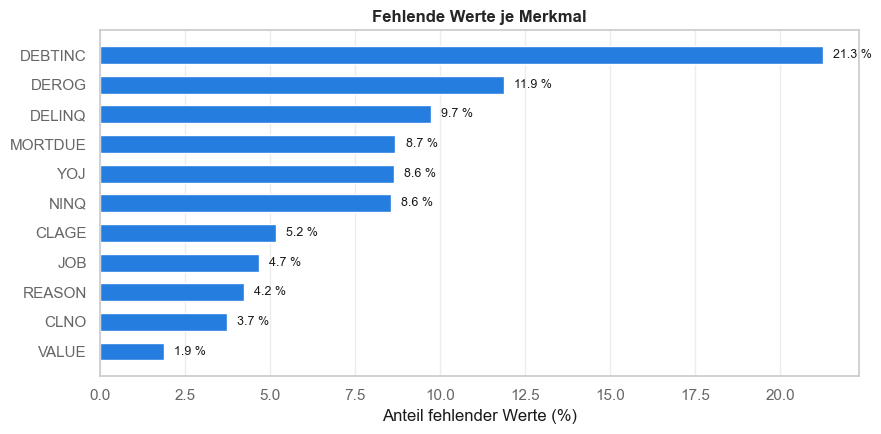

In [28]:
m = missing[missing["fehlend"] > 0]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(m.index[::-1], m["fehlend_%"][::-1], color=C_GOOD, height=0.6)
for i, v in enumerate(m["fehlend_%"][::-1]):
    ax.text(v + 0.3, i, f"{v:.1f} %", va="center", fontsize=9, color="#191919")
ax.set_xlabel("Anteil fehlender Werte (%)")
ax.set_title("Fehlende Werte je Merkmal")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

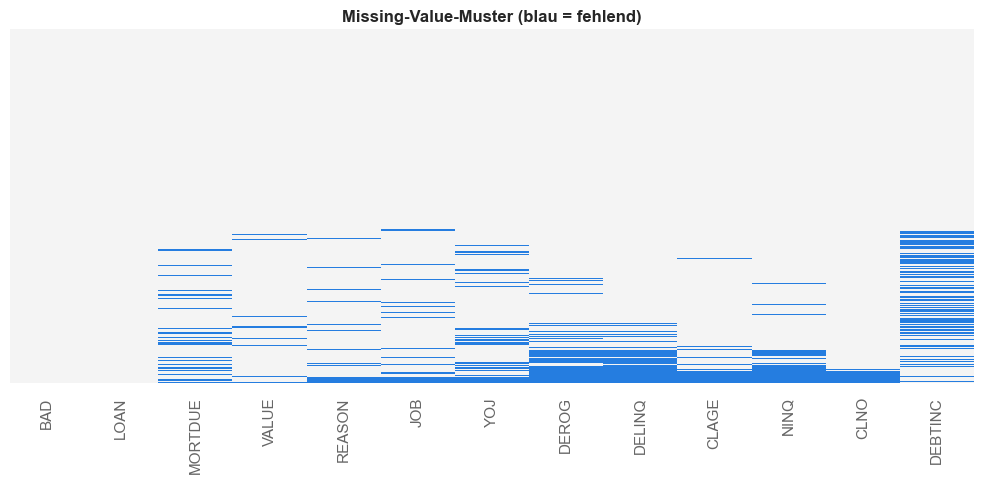

In [29]:
# Muster der fehlenden Werte (jede Zeile = ein Kredit, sortiert nach Anzahl fehlender Werte)
order = df.isnull().sum(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.loc[order].isnull(), cbar=False, yticklabels=False,
            cmap=mcolors.ListedColormap(["#f4f4f4", C_GOOD]), ax=ax)
ax.set_title("Missing-Value-Muster (blau = fehlend)")
plt.tight_layout(); plt.show()

In [30]:
# Wie viele Werte fehlen pro Zeile?
na_per_row = df.isnull().sum(axis=1)
na_per_row.value_counts().sort_index().rename_axis("fehlende Werte je Zeile").to_frame("Anzahl Zeilen")

,Anzahl Zeilen
fehlende Werte je Zeile,
0,3364
1,1589
2,449
3,219
4,64
5,83
6,66
7,25
8,39


### Hängt das Fehlen mit der Zielvariable zusammen?
Für ein Kreditrisikomodell ist wichtig, ob Werte *zufällig* fehlen oder ob das Fehlen selbst Information trägt.
Dazu vergleichen wir die Ausfallrate zwischen Zeilen mit und ohne fehlenden Wert.

In [31]:
rows = []
for c in df.columns.drop(TARGET):
    is_na = df[c].isnull()
    if is_na.any():
        rows.append({
            "Merkmal": c,
            "Ausfallrate wenn fehlend": df.loc[is_na, TARGET].mean(),
            "Ausfallrate wenn vorhanden": df.loc[~is_na, TARGET].mean(),
        })
na_target = pd.DataFrame(rows).set_index("Merkmal")
na_target["Differenz (pp)"] = (na_target.iloc[:, 0] - na_target.iloc[:, 1]) * 100
na_target.sort_values("Differenz (pp)", ascending=False).style.format(
    {"Ausfallrate wenn fehlend": "{:.1%}", "Ausfallrate wenn vorhanden": "{:.1%}", "Differenz (pp)": "{:+.1f}"})

,Ausfallrate wenn fehlend,Ausfallrate wenn vorhanden,Differenz (pp)
Merkmal,,,
VALUE,93.8%,18.5%,+75.2
DEBTINC,62.0%,8.6%,+53.4
CLAGE,25.3%,19.7%,+5.7
CLNO,23.9%,19.8%,+4.1
MORTDUE,20.5%,19.9%,+0.6
REASON,19.0%,20.0%,-0.9
NINQ,14.7%,20.4%,-5.7
YOJ,12.6%,20.6%,-8.0
DELINQ,12.4%,20.8%,-8.3


## 5. Zielvariable `BAD`

     Anzahl Anteil
BAD               
0      4771  80.1%
1      1189  19.9%


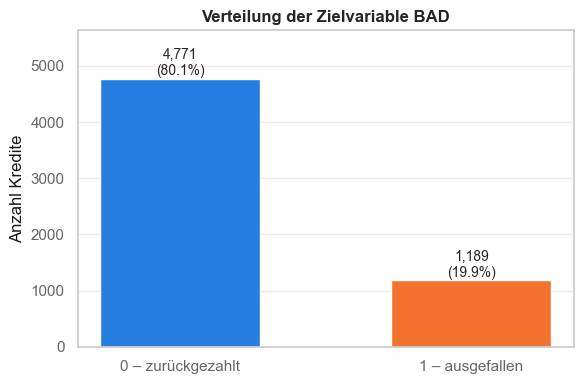

In [32]:
counts = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({"Anzahl": counts, "Anteil": (counts / len(df)).map("{:.1%}".format)}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["0 – zurückgezahlt", "1 – ausgefallen"], counts.values, color=[C_GOOD, C_BAD], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=10)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Anzahl Kredite")
ax.set_title("Verteilung der Zielvariable BAD")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 6. Numerische Merkmale

### Deskriptive Statistik

In [33]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
LOAN,"5,960.00","18,607.97","11,207.48","1,100.00","11,100.00","16,300.00","23,300.00","89,900.00"
MORTDUE,"5,442.00","73,760.82","44,457.61","2,063.00","46,276.00","65,019.00","91,488.00","399,550.00"
VALUE,"5,848.00","101,776.05","57,385.78","8,000.00","66,075.50","89,235.50","119,824.25","855,909.00"
YOJ,"5,445.00",8.92,7.57,0.00,3.00,7.00,13.00,41.00
DEROG,"5,252.00",0.25,0.85,0.00,0.00,0.00,0.00,10.00
DELINQ,"5,380.00",0.45,1.13,0.00,0.00,0.00,0.00,15.00
CLAGE,"5,652.00",179.77,85.81,0.00,115.12,173.47,231.56,"1,168.23"
NINQ,"5,450.00",1.19,1.73,0.00,0.00,1.00,2.00,17.00
CLNO,"5,738.00",21.30,10.14,0.00,15.00,20.00,26.00,71.00
DEBTINC,"4,693.00",33.78,8.60,0.52,29.14,34.82,39.00,203.31


In [34]:
# Zusätzliche Kennzahlen: Schiefe, Kurtosis, Anteil Nullen
pd.DataFrame({
    "Schiefe": df[num_cols].skew(),
    "Kurtosis": df[num_cols].kurt(),
    "Anteil Nullen": (df[num_cols] == 0).mean().map("{:.1%}".format),
}).sort_values("Schiefe", ascending=False)

,Schiefe,Kurtosis,Anteil Nullen
DEROG,5.32,36.87,76.0%
DELINQ,4.02,23.57,70.1%
VALUE,3.05,24.36,0.0%
DEBTINC,2.85,50.50,0.0%
NINQ,2.62,9.79,42.5%
LOAN,2.02,6.93,0.0%
MORTDUE,1.81,6.48,0.0%
CLAGE,1.34,7.60,0.0%
YOJ,0.99,0.37,7.0%
CLNO,0.78,1.16,1.0%


### Verteilungen (Histogramme)

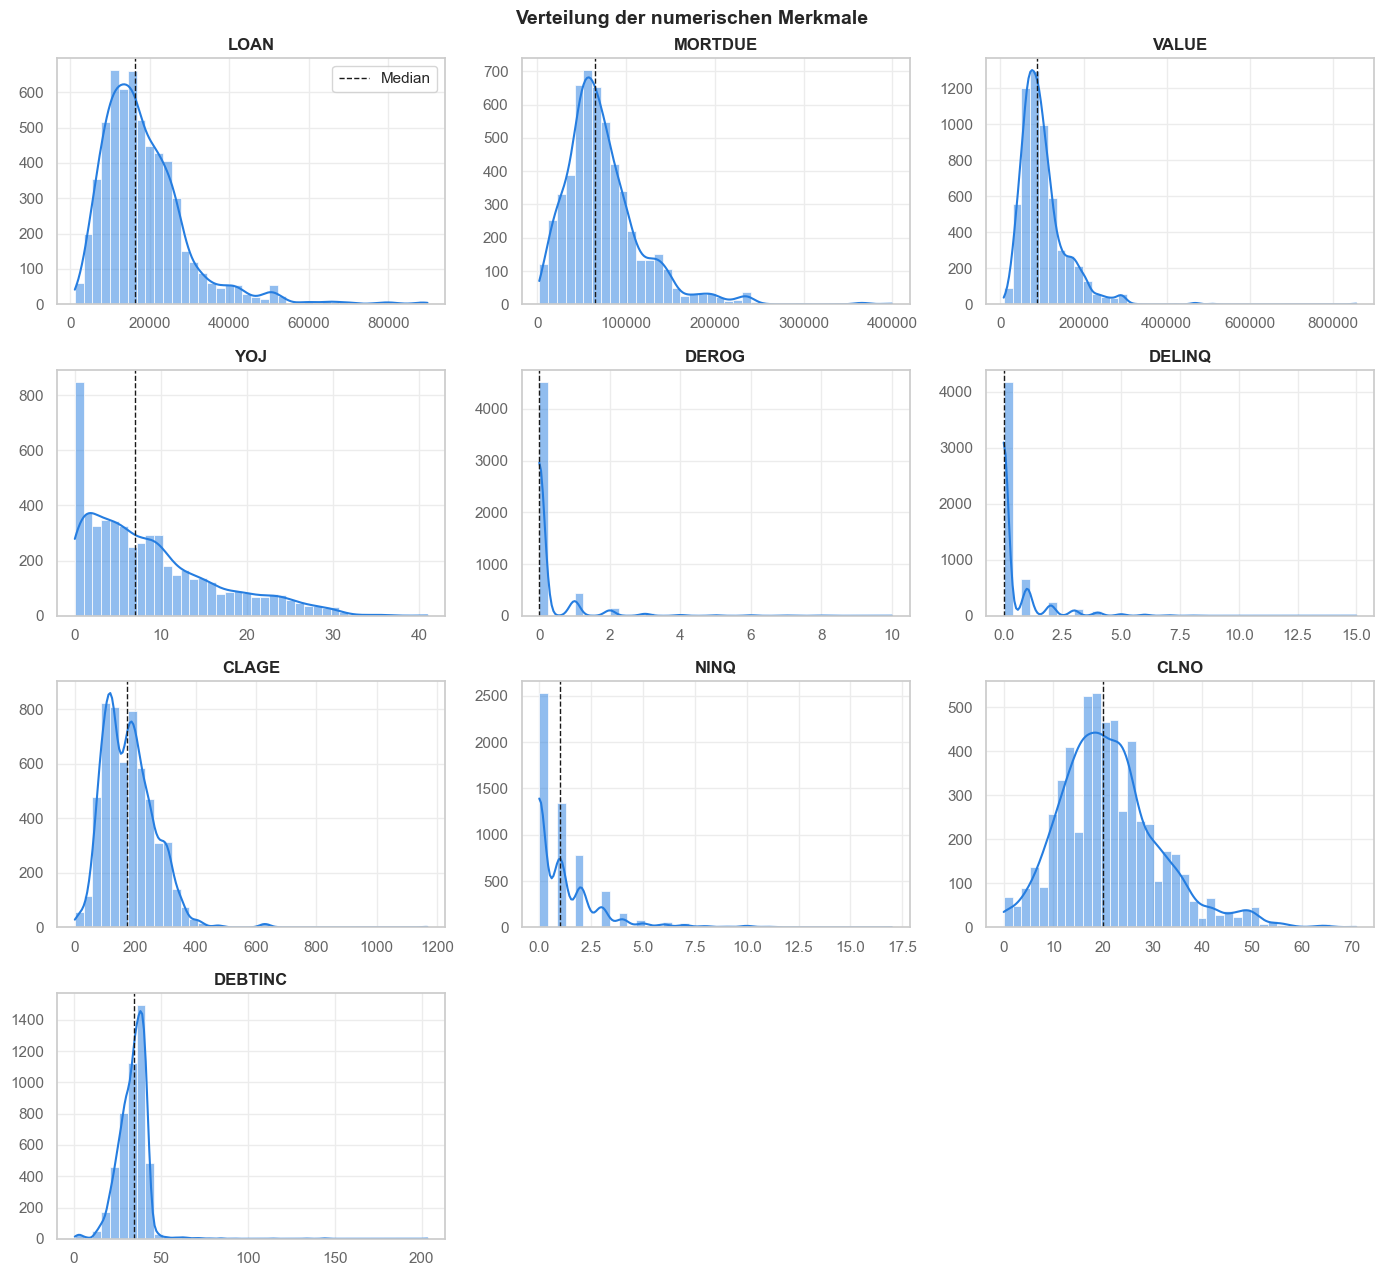

In [35]:
fig, axes = plt.subplots(4, 3, figsize=(14, 13))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c].dropna(), bins=40, kde=True, color=C_GOOD, ax=ax, edgecolor="white", linewidth=0.5)
    ax.axvline(df[c].median(), color="#191919", ls="--", lw=1, label="Median")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
axes.flat[0].legend()
for ax in axes.flat[len(num_cols):]:
    ax.remove()
fig.suptitle("Verteilung der numerischen Merkmale", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### Boxplots und Ausreißer

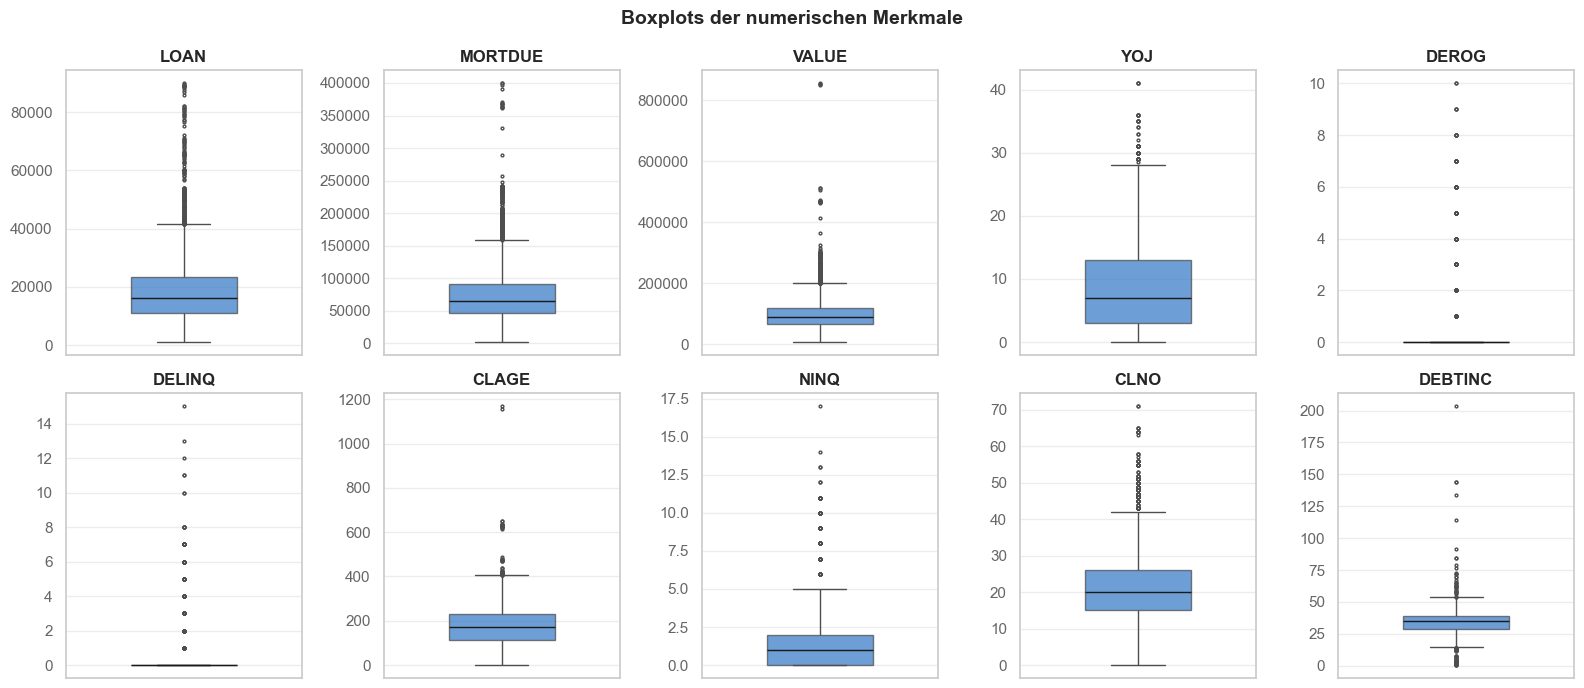

In [36]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(y=df[c], color=C_GOOD, ax=ax, width=0.45, fliersize=2,
                boxprops=dict(alpha=0.75), medianprops=dict(color="#191919"))
    ax.set_title(c); ax.set_ylabel("")
fig.suptitle("Boxplots der numerischen Merkmale", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [37]:
# Ausreißer nach IQR-Regel (außerhalb von Q1 − 1,5·IQR bzw. Q3 + 1,5·IQR)
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < lo) | (s > hi)).sum()
    return pd.Series({"untere Grenze": lo, "obere Grenze": hi, "Ausreißer": n, "Ausreißer_%": n / s.notna().sum() * 100})

df[num_cols].apply(iqr_outliers).T.sort_values("Ausreißer_%", ascending=False)

,untere Grenze,obere Grenze,Ausreißer,Ausreißer_%
DELINQ,0.00,0.00,"1,201.00",22.32
DEROG,0.00,0.00,725.00,13.80
VALUE,"-14,547.62","200,447.38",320.00,5.47
MORTDUE,"-21,542.00","159,306.00",234.00,4.30
LOAN,"-7,200.00","41,600.00",256.00,4.30
CLNO,-1.50,42.50,219.00,3.82
NINQ,-3.00,5.00,177.00,3.25
DEBTINC,14.35,53.80,94.00,2.00
YOJ,-12.00,28.00,91.00,1.67
CLAGE,-59.55,406.23,47.00,0.83


*Hinweis:* `DEROG`, `DELINQ` und `NINQ` sind Zählvariablen mit sehr vielen Nullen – dort markiert die IQR-Regel
praktisch jeden Wert > 0 als „Ausreißer“. Das sind keine Datenfehler, sondern genau die informativen Fälle.

In [38]:
# Diskrete Zählvariablen genauer ansehen
for c in ["DEROG", "DELINQ", "NINQ"]:
    print(f"\n{c}:")
    print(df[c].value_counts(dropna=False).sort_index().to_string())


DEROG:
DEROG
0.00     4527
1.00      435
2.00      160
3.00       58
4.00       23
5.00       15
6.00       15
7.00        8
8.00        6
9.00        3
10.00       2
NaN       708

DELINQ:
DELINQ
0.00     4179
1.00      654
2.00      250
3.00      129
4.00       78
5.00       38
6.00       27
7.00       13
8.00        5
10.00       2
11.00       2
12.00       1
13.00       1
15.00       1
NaN       580

NINQ:
NINQ
0.00     2531
1.00     1339
2.00      780
3.00      392
4.00      156
5.00       75
6.00       56
7.00       44
8.00       22
9.00       11
10.00      28
11.00      10
12.00       2
13.00       2
14.00       1
17.00       1
NaN       510


In [39]:
# Auffällige Extremwerte prüfen
print("Größte DEBTINC-Werte:\n", df["DEBTINC"].nlargest(5).round(1).to_string())
print("\nGrößte CLAGE-Werte (Monate):\n", df["CLAGE"].nlargest(5).round(1).to_string())
print("\nKredite, bei denen die Hypothek den Immobilienwert übersteigt:", (df["MORTDUE"] > df["VALUE"]).sum())

Größte DEBTINC-Werte:
 4473   203.30
5912   144.20
3910   143.90
4423   133.50
5599   114.10

Größte CLAGE-Werte (Monate):
 3679   1,168.20
3097   1,154.60
4470     649.70
4536     648.30
4264     639.10

Kredite, bei denen die Hypothek den Immobilienwert übersteigt: 51


## 7. Kategoriale Merkmale

In [40]:
for c in cat_cols:
    vc = df[c].value_counts(dropna=False)
    print(pd.DataFrame({"Anzahl": vc, "Anteil": (vc / len(df)).map("{:.1%}".format)}), "\n")

         Anzahl Anteil
REASON                
DebtCon    3928  65.9%
HomeImp    1780  29.9%
NaN         252   4.2% 

         Anzahl Anteil
JOB                   
Other      2388  40.1%
ProfExe    1276  21.4%
Office      948  15.9%
Mgr         767  12.9%
NaN         279   4.7%
Self        193   3.2%
Sales       109   1.8% 



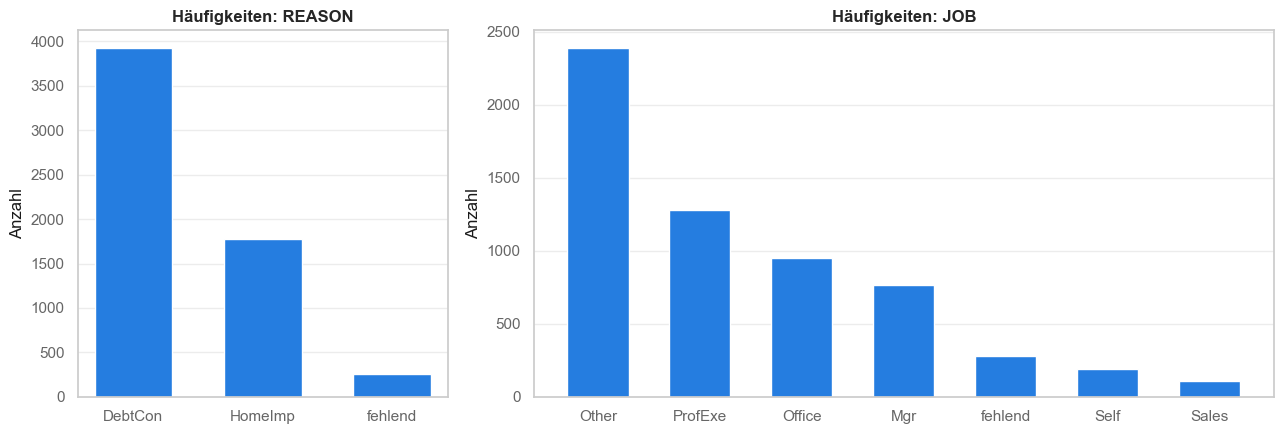

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2]})
for ax, c in zip(axes, cat_cols):
    vc = df[c].fillna("fehlend").value_counts()
    ax.bar(vc.index, vc.values, color=C_GOOD, width=0.6)
    ax.set_title(f"Häufigkeiten: {c}"); ax.set_ylabel("Anzahl")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 8. Bivariate Analyse: Merkmale vs. Zielvariable

### Numerische Merkmale nach `BAD`

In [42]:
df.groupby(TARGET)[num_cols].median().T.rename(columns={0: "Median BAD=0", 1: "Median BAD=1"})

BAD,Median BAD=0,Median BAD=1
LOAN,"16,900.00","14,900.00"
MORTDUE,"66,839.00","60,279.00"
VALUE,"90,659.00","82,000.00"
YOJ,7.00,6.00
DEROG,0.00,0.00
DELINQ,0.00,0.00
CLAGE,180.42,132.87
NINQ,1.00,1.00
CLNO,20.00,20.00
DEBTINC,34.54,38.08


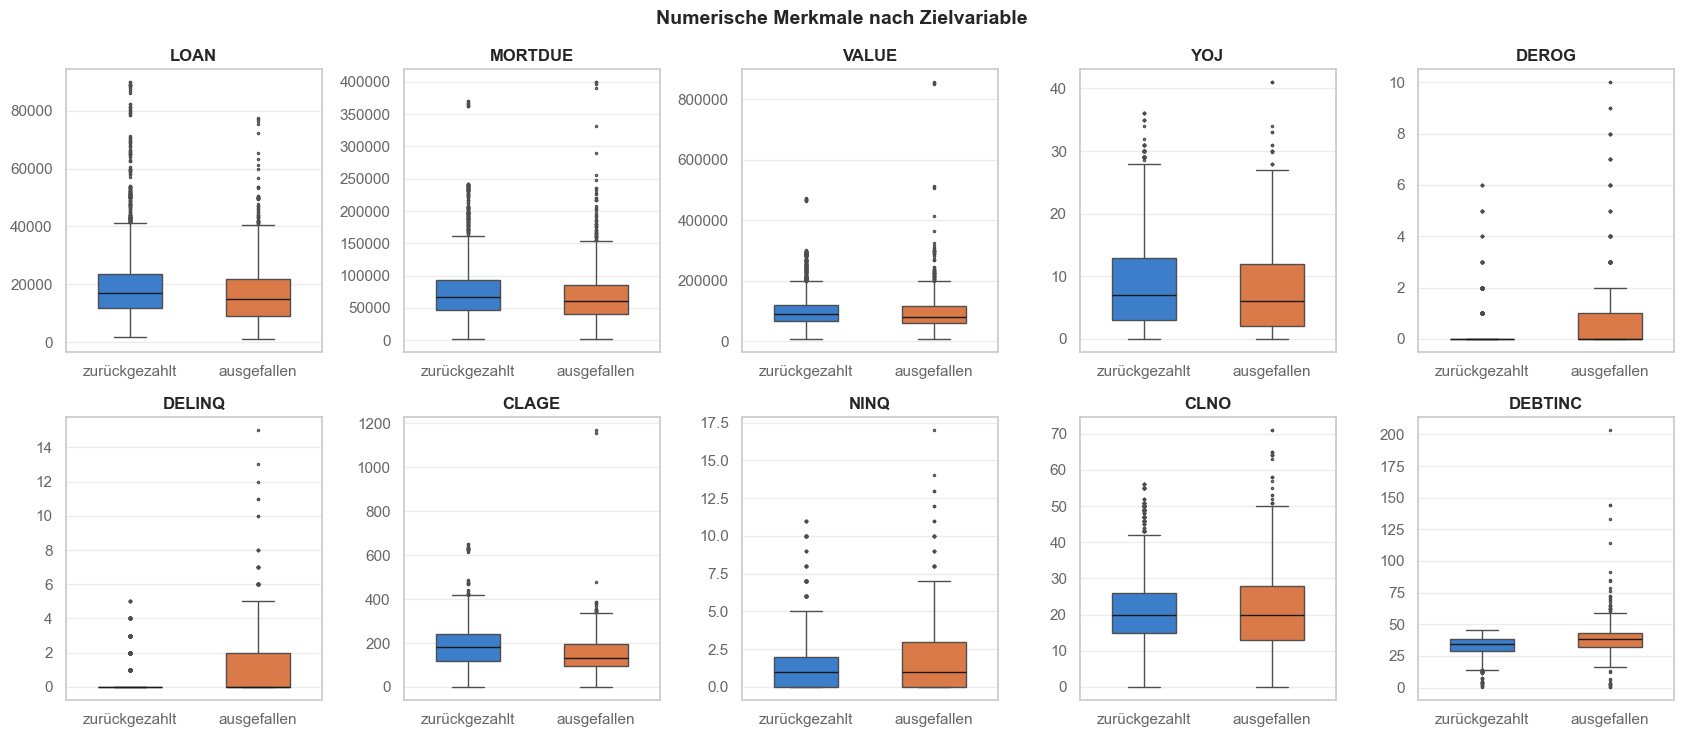

In [43]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=PALETTE_BAD, legend=False,
                ax=ax, width=0.5, fliersize=1.5, medianprops=dict(color="#191919"))
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticks([0, 1], ["zurückgezahlt", "ausgefallen"])
fig.suptitle("Numerische Merkmale nach Zielvariable", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

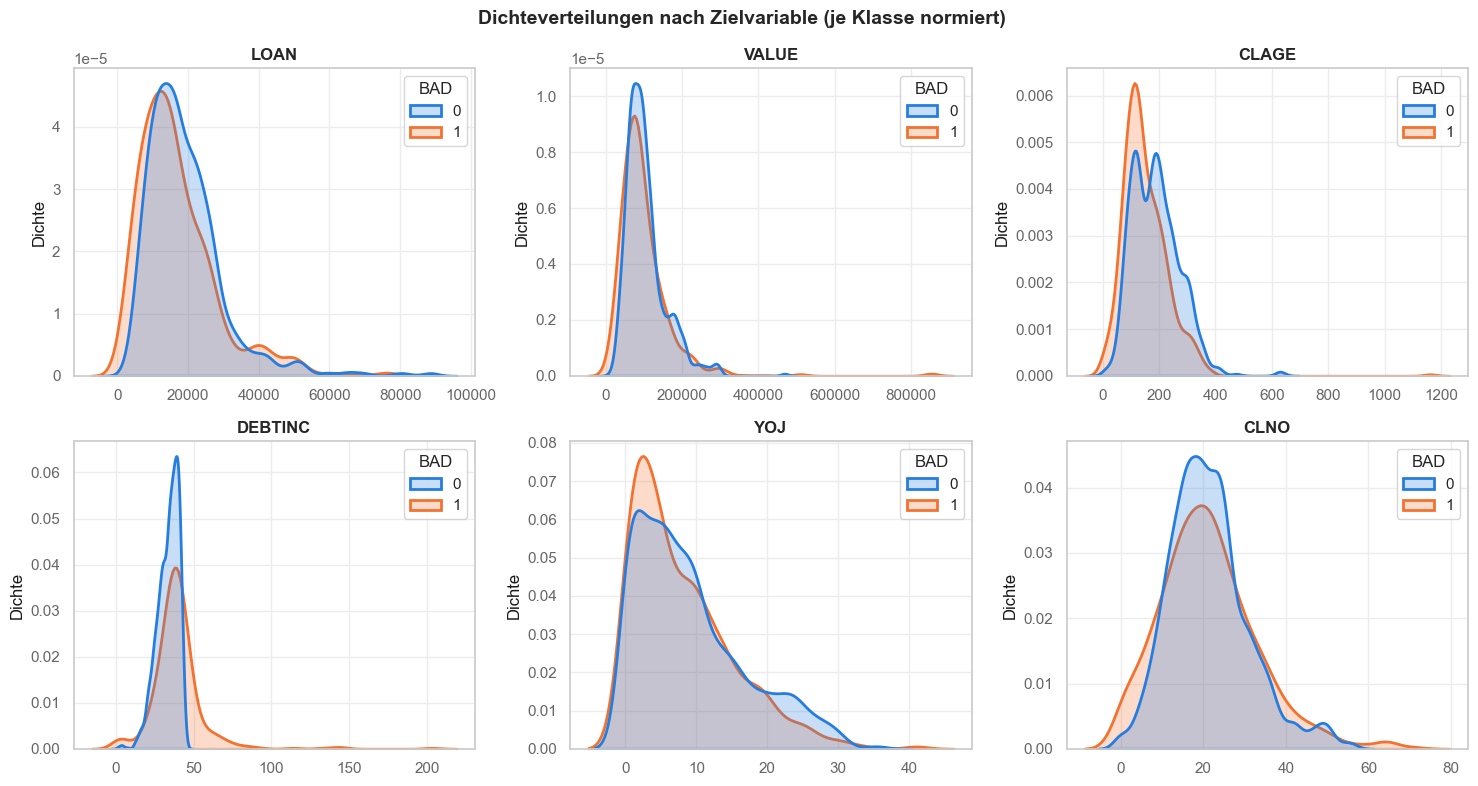

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, ["LOAN", "VALUE", "CLAGE", "DEBTINC", "YOJ", "CLNO"]):
    sns.kdeplot(data=df, x=c, hue=TARGET, palette=PALETTE_BAD, common_norm=False,
                fill=True, alpha=0.25, linewidth=2, ax=ax)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("Dichte")
    ax.get_legend().set_title("BAD")
fig.suptitle("Dichteverteilungen nach Zielvariable (je Klasse normiert)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

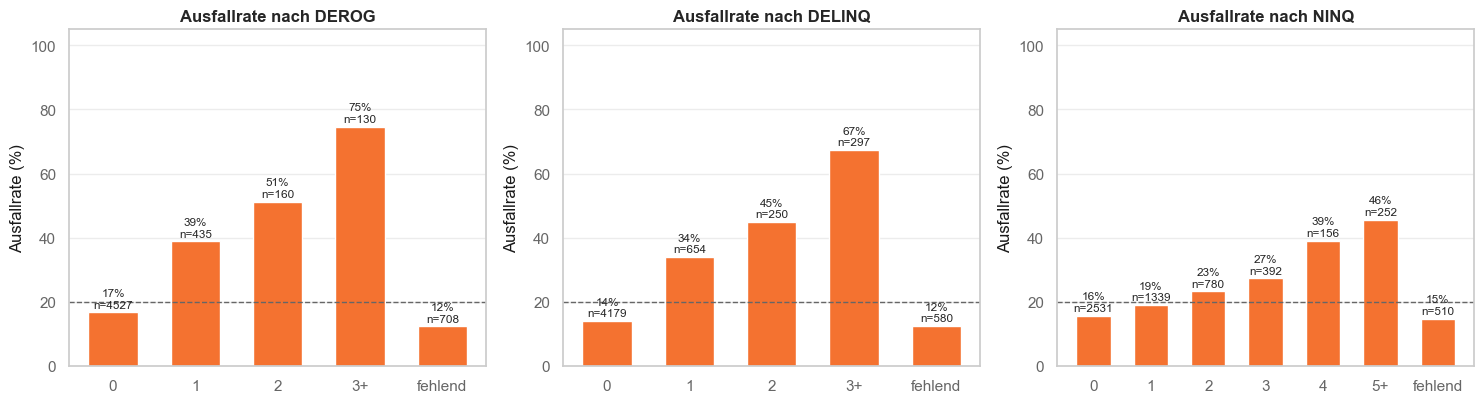

In [45]:
# Ausfallrate in Abhängigkeit der Zählvariablen (Werte ab 3 bzw. 5 zusammengefasst)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (c, cap) in zip(axes, [("DEROG", 3), ("DELINQ", 3), ("NINQ", 5)]):
    g = df[c].clip(upper=cap).map(lambda v: "fehlend" if pd.isna(v) else (f"{int(v)}+" if v == cap else str(int(v))))
    rate = df.groupby(g)[TARGET].agg(["mean", "size"])
    rate = rate.loc[[i for i in [str(k) for k in range(cap)] + [f"{cap}+", "fehlend"] if i in rate.index]]
    ax.bar(rate.index, rate["mean"] * 100, color=C_BAD, width=0.6)
    for i, (r, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, r * 100 + 1.5, f"{r:.0%}\nn={n}", ha="center", fontsize=8.5)
    ax.axhline(df[TARGET].mean() * 100, color="#666666", ls="--", lw=1)
    ax.set_ylim(0, 105); ax.set_title(f"Ausfallrate nach {c}"); ax.set_ylabel("Ausfallrate (%)")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### Kategoriale Merkmale nach `BAD`

In [46]:
for c in cat_cols:
    ct = pd.crosstab(df[c].fillna("fehlend"), df[TARGET], margins=True)
    ct["Ausfallrate"] = (ct[1] / ct["All"]).map("{:.1%}".format)
    print(ct, "\n")

BAD         0     1   All Ausfallrate
REASON                               
DebtCon  3183   745  3928       19.0%
HomeImp  1384   396  1780       22.2%
fehlend   204    48   252       19.0%
All      4771  1189  5960       19.9% 

BAD         0     1   All Ausfallrate
JOB                                  
Mgr       588   179   767       23.3%
Office    823   125   948       13.2%
Other    1834   554  2388       23.2%
ProfExe  1064   212  1276       16.6%
Sales      71    38   109       34.9%
Self      135    58   193       30.1%
fehlend   256    23   279        8.2%
All      4771  1189  5960       19.9% 



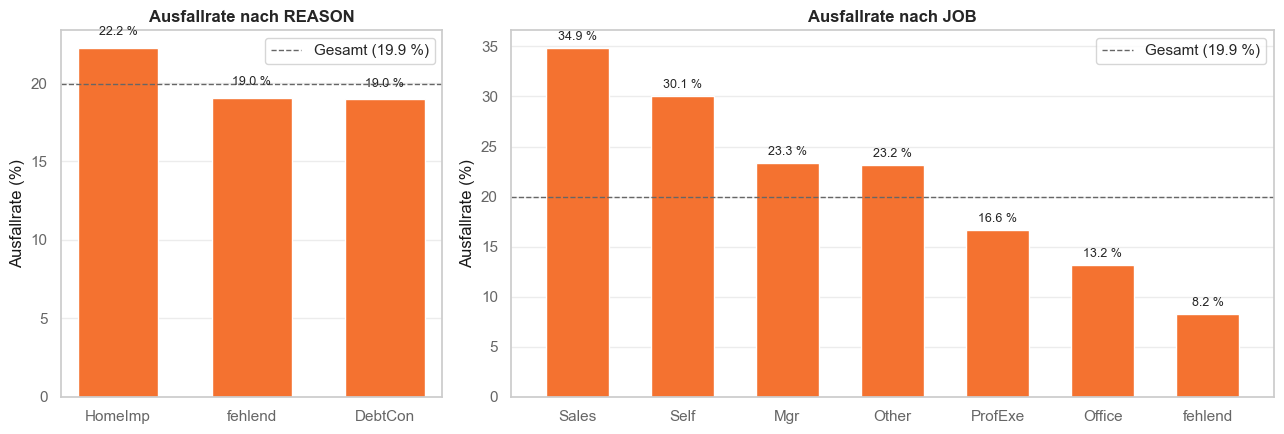

In [47]:
overall = df[TARGET].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2]})
for ax, c in zip(axes, cat_cols):
    rate = df.groupby(df[c].fillna("fehlend"))[TARGET].mean().sort_values(ascending=False) * 100
    ax.bar(rate.index, rate.values, color=C_BAD, width=0.6)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f} %", ha="center", fontsize=9)
    ax.axhline(overall, color="#666666", ls="--", lw=1, label=f"Gesamt ({overall:.1f} %)")
    ax.set_title(f"Ausfallrate nach {c}"); ax.set_ylabel("Ausfallrate (%)")
    ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 9. Korrelationen

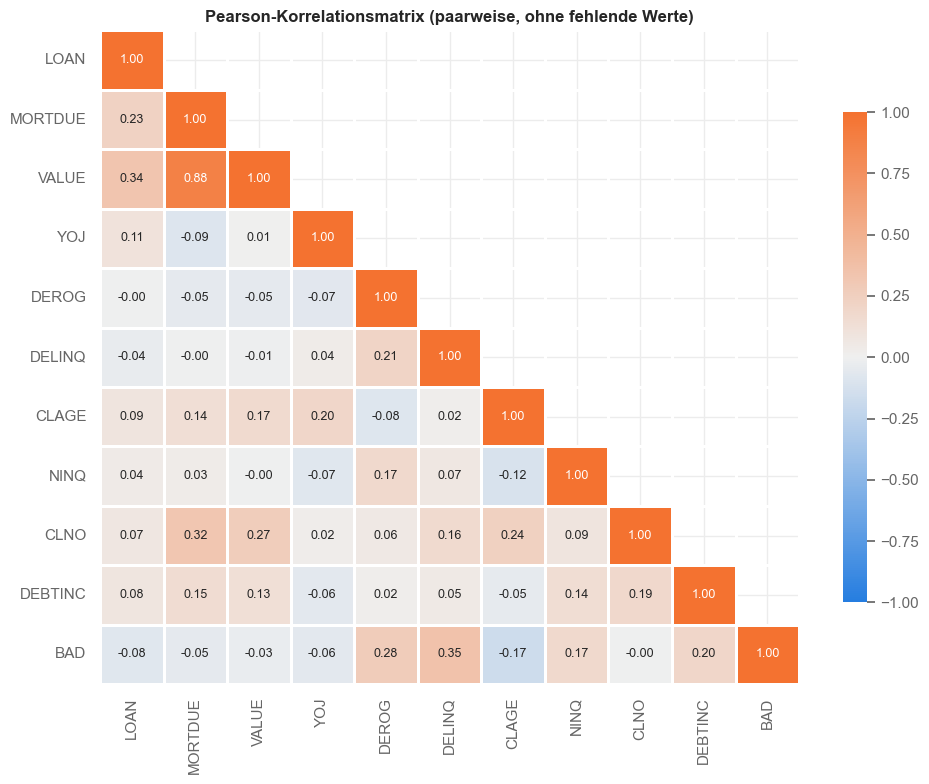

In [48]:
corr = df[num_cols + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.75}, annot_kws={"size": 9}, ax=ax)
ax.set_title("Pearson-Korrelationsmatrix (paarweise, ohne fehlende Werte)")
plt.tight_layout(); plt.show()

In [49]:
# Korrelation mit der Zielvariable (Pearson und rangbasiert nach Spearman)
pd.DataFrame({
    "Pearson": df[num_cols].corrwith(df[TARGET]),
    "Spearman": df[num_cols].corrwith(df[TARGET], method="spearman"),
}).sort_values("Pearson", key=abs, ascending=False)

,Pearson,Spearman
DELINQ,0.35,0.33
DEROG,0.28,0.27
DEBTINC,0.20,0.15
NINQ,0.17,0.15
CLAGE,-0.17,-0.19
LOAN,-0.08,-0.11
YOJ,-0.06,-0.06
MORTDUE,-0.05,-0.08
VALUE,-0.03,-0.08
CLNO,-0.00,-0.01


In [50]:
# Stark korrelierte Merkmalspaare (|r| > 0,5)
pairs = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack()
pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).to_frame("r")

,,r
MORTDUE,VALUE,0.88


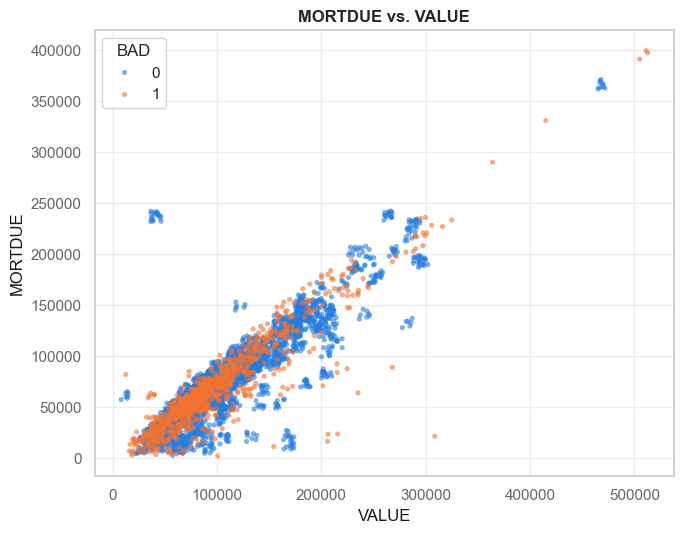

In [51]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.scatterplot(data=df.sort_values(TARGET), x="VALUE", y="MORTDUE", hue=TARGET, palette=PALETTE_BAD,
                s=14, alpha=0.6, edgecolor="none", ax=ax)
ax.set_title("MORTDUE vs. VALUE"); ax.get_legend().set_title("BAD")
plt.tight_layout(); plt.show()

## 10. Zusammenfassung der Erkenntnisse

**Datenqualität**
- 5.960 Kredite, 13 Spalten (10 numerisch, 2 kategorial, 1 binäres Ziel), keine Duplikate.
- 11 von 13 Spalten haben fehlende Werte; nur 3.364 Zeilen (56 %) sind vollständig. Am stärksten betroffen: `DEBTINC` (21,3 %), `DEROG` (11,9 %), `DELINQ` (9,7 %).
- **Das Fehlen ist informativ, nicht zufällig:** Fehlt `DEBTINC`, liegt die Ausfallrate bei ~62 % (sonst ~9 %); fehlt `VALUE`, sogar bei ~94 %. Ein einfaches Löschen der Zeilen würde also gezielt Ausfälle entfernen. Für die Modellierung bieten sich Missing-Indikatoren plus Imputation an.
- Auffällige Extremwerte: `DEBTINC` bis 203 %, `CLAGE` bis ~1.168 Monate (≈ 97 Jahre, unplausibel) und 51 Kredite mit `MORTDUE` > `VALUE`.

**Zielvariable**
- Unausgewogen: 80,1 % zurückgezahlt vs. 19,9 % ausgefallen. Für Modelle stratifiziert splitten und Metriken wie ROC-AUC, PR-AUC oder F1 statt Accuracy verwenden.

**Verteilungen**
- Fast alle Geldbeträge (`LOAN`, `MORTDUE`, `VALUE`) sind deutlich rechtsschief; eine Log-Transformation kann für lineare Modelle sinnvoll sein.
- `DEROG` und `DELINQ` sind zu 76 % bzw. 70 % null; die IQR-„Ausreißer“ sind hier inhaltlich die relevanten Fälle.

**Zusammenhänge mit `BAD`**
- Stärkste Einzelsignale: `DELINQ` (r = 0,35) und `DEROG` (r = 0,28). Schon ein negativer Eintrag verdoppelt die Ausfallrate grob, ab 3 Einträgen liegt sie bei 67–75 %.
- Höhere `DEBTINC` und mehr Kreditanfragen (`NINQ`) gehen mit mehr Ausfällen einher; ältere Kreditlinien (`CLAGE`) mit weniger.
- Kreditbetrag, Immobilienwert und Anzahl Kreditlinien unterscheiden sich zwischen den Klassen kaum.
- Berufsgruppe: `Sales` (34,9 %) und `Self` (30,1 %) fallen am häufigsten aus, `Office` (13,2 %) am seltensten. Beim Kreditzweck ist `HomeImp` (22,2 %) leicht riskanter als `DebtCon` (19,0 %).

**Multikollinearität**
- `MORTDUE` und `VALUE` korrelieren stark (r = 0,88). Für Modelle und vor allem für Erklärungsverfahren (z. B. Permutation Importance, SHAP) sollte man das berücksichtigen, etwa über ein abgeleitetes Merkmal wie Loan-to-Value.